# Разведочный анализ: поездки Divvy по районам Чикаго

Данные берутся из витрины `daily_area` (район × день), которую строит `make mart`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from shapely import wkt

from src.config import load_config

cfg = load_config()
con = duckdb.connect(cfg['paths']['db'], read_only=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.3})

df = con.execute('select * from daily_area').df()
df['date'] = pd.to_datetime(df['date'])
print(f"Строк: {len(df):,}, районов: {df.area_num.nunique()}, период: {df.date.min():%Y-%m-%d} — {df.date.max():%Y-%m-%d}")
print(f"Всего поездок в витрине: {df.n_trips.sum():,}")

Строк: 79,695, районов: 77, период: 2024-01-01 — 2026-10-31
Всего поездок в витрине: 16,490,127


## 1. Журнал загрузок и контроль качества

In [2]:
con.execute('''
    select source, status, count(*) as runs, sum(rows_loaded) as rows_loaded,
           min(started_at) as first_run, max(started_at) as last_run
    from load_log group by all order by source, status
''').df()

,source,status,runs,rows_loaded,first_run,last_run
0,areas,skipped,5,0.0,2026-10-15 16:43:14.111895,2026-11-11 17:04:58.729942
1,areas,success,1,77.0,2026-10-15 16:31:09.409146,2026-10-15 16:31:09.409146
2,divvy,success,40,17211323.0,2026-10-15 16:31:23.565066,2026-11-11 17:04:58.835144
3,gbfs,success,12,24928.0,2026-10-15 16:31:19.342604,2026-11-11 17:04:59.513687
4,holidays,success,6,354.0,2026-10-15 16:31:17.069783,2026-11-11 17:04:58.740561
5,open-meteo,skipped,4,0.0,2026-10-15 16:43:14.301561,2026-11-11 17:04:58.826993
6,open-meteo,success,2,1040.0,2026-10-15 16:31:18.013651,2026-11-11 16:42:42.428039


In [3]:
con.execute('''
    select layer, check_name, round(value, 4) as value, threshold, passed
    from dq_report where checked_at = (select max(checked_at) from dq_report)
''').df()

,layer,check_name,value,threshold,passed
0,raw,rows,1.721085e+07,1.000,True
1,raw,share_null_coords,0.000000e+00,0.010,True
2,raw,share_duplicate_ride_id,0.000000e+00,0.001,True
3,raw,share_non_positive_duration,0.000000e+00,0.010,True
4,raw,share_without_station,2.009000e-01,0.500,True
5,clean,share_rows_kept,9.581000e-01,0.900,True
6,clean,missing_dates,0.000000e+00,0.000,True


## 2. Динамика спроса и погода

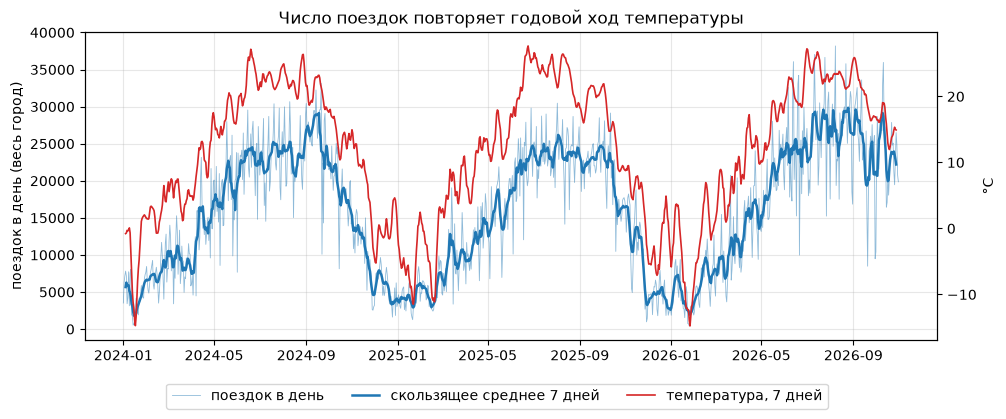

In [4]:
city = df.groupby('date').agg(n_trips=('n_trips', 'sum'), temp=('temperature_2m_mean', 'first'),
                              precip=('precipitation_sum', 'first')).reset_index()

fig, ax = plt.subplots()
ax.plot(city.date, city.n_trips, lw=0.6, color='tab:blue', alpha=0.5, label='поездок в день')
ax.plot(city.date, city.n_trips.rolling(7, center=True).mean(), lw=1.8, color='tab:blue', label='скользящее среднее 7 дней')
ax.set_ylabel('поездок в день (весь город)')
ax2 = ax.twinx()
ax2.plot(city.date, city.temp.rolling(7, center=True).mean(), color='tab:red', lw=1.2, label='температура, 7 дней')
ax2.set_ylabel('°C'); ax2.grid(False)
fig.legend(loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
ax.set_title('Число поездок повторяет годовой ход температуры')
plt.show()

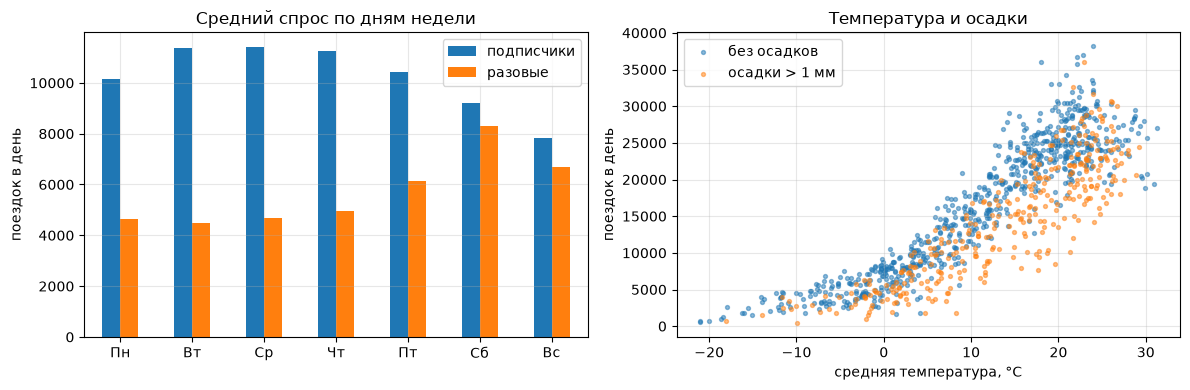

Корреляция поездок с температурой: 0.877
Дождливый день в среднем: 14,419 поездок, сухой: 16,660


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

wd = df.assign(dow=df.date.dt.dayofweek).groupby(['date', 'dow'])[['n_member', 'n_casual']].sum().groupby('dow').mean()
wd.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
wd.columns = ['подписчики', 'разовые']
wd.plot.bar(ax=axes[0], rot=0)
axes[0].set_title('Средний спрос по дням недели'); axes[0].set_ylabel('поездок в день')

rain = city.precip > 1
axes[1].scatter(city.temp[~rain], city.n_trips[~rain], s=8, alpha=0.5, label='без осадков')
axes[1].scatter(city.temp[rain], city.n_trips[rain], s=8, alpha=0.5, color='tab:orange', label='осадки > 1 мм')
axes[1].set_xlabel('средняя температура, °C'); axes[1].set_ylabel('поездок в день')
axes[1].set_title('Температура и осадки'); axes[1].legend()
plt.tight_layout(); plt.show()

print('Корреляция поездок с температурой:', round(city.n_trips.corr(city.temp), 3))
print(f"Дождливый день в среднем: {city.n_trips[rain].mean():,.0f} поездок, сухой: {city.n_trips[~rain].mean():,.0f}")

## 3. Районы

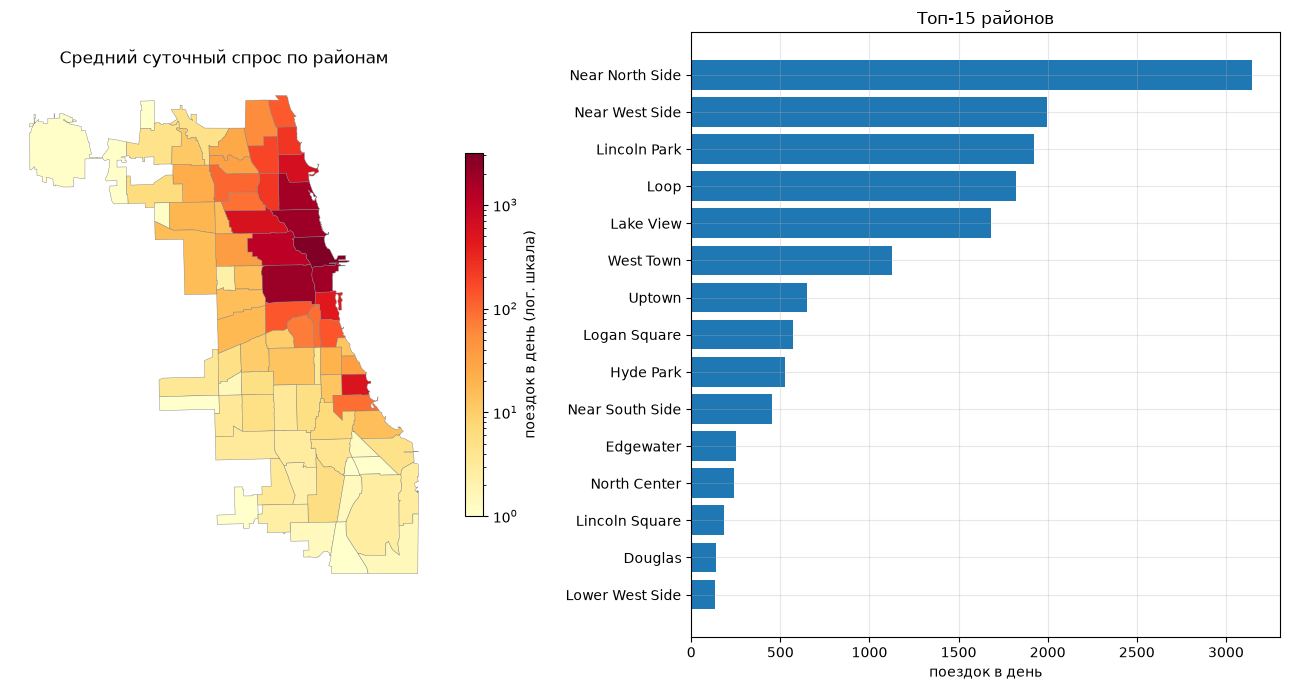

На 10 районов из 77 приходится 87% поездок
Районов, где больше половины дней без поездок: 6


In [6]:
by_area = (df.groupby(['area_num', 'area_name'])
             .agg(mean_daily=('n_trips', 'mean'), zero_share=('n_trips', lambda s: (s == 0).mean()))
             .reset_index().sort_values('mean_daily', ascending=False))
areas = con.execute('select area_num, geometry from areas').df().merge(by_area, on='area_num')

fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={'width_ratios': [1, 1.1]})

patches, values = [], []
for _, r in areas.iterrows():
    geom = wkt.loads(r.geometry)
    for poly in getattr(geom, 'geoms', [geom]):
        patches.append(MplPolygon(list(poly.exterior.coords)))
        values.append(r.mean_daily)
pc = PatchCollection(patches, cmap='YlOrRd', edgecolor='grey', linewidth=0.3, norm=plt.matplotlib.colors.LogNorm())
pc.set_array(pd.Series(values).clip(lower=1))
axes[0].add_collection(pc); axes[0].autoscale(); axes[0].set_aspect(1.35); axes[0].axis('off')
fig.colorbar(pc, ax=axes[0], shrink=0.6, label='поездок в день (лог. шкала)')
axes[0].set_title('Средний суточный спрос по районам')

top = by_area.head(15).iloc[::-1]
axes[1].barh(top.area_name, top.mean_daily)
axes[1].set_title('Топ-15 районов'); axes[1].set_xlabel('поездок в день')
plt.tight_layout(); plt.show()

share_top10 = by_area.head(10).mean_daily.sum() / by_area.mean_daily.sum()
print(f'На 10 районов из {len(by_area)} приходится {share_top10:.0%} поездок')
print(f'Районов, где больше половины дней без поездок: {(by_area.zero_share > 0.5).sum()}')

## 4. Слабоструктурированный источник: снимки GBFS

In [7]:
con.execute('''
    select count(distinct snapshot_ts) as snapshots, count(distinct station_id) as stations,
           round(avg(case when num_bikes_available = 0 then 1 else 0 end), 3) as share_empty,
           round(avg(case when num_docks_available = 0 then 1 else 0 end), 3) as share_full
    from gbfs_status
''').df()

,snapshots,stations,share_empty,share_full
0,6,2082,0.429,0.043


## Выводы

1. **Объём.** За 01.2024–09.2026 загружено 16,4 млн поездок. После очистки 95,8% из них привязаны к 77 районам; проверки качества пройдены, пропущенных дат нет.
2. **Сезонность и погода.** Корреляция суточного спроса с температурой 0,88, так что погода — главный внешний признак. Осадки снижают спрос: в среднем 14,3 тыс. поездок против 16,4 тыс. в сухой день, а при одинаковой температуре разница ещё заметнее.
3. **Недельный цикл у групп пользователей противоположный.** Подписчики ездят в будни (на работу), разовые пользователи — в выходные. Значит, нужны лаг 7 дней и день недели, а доли подписчиков и разовых пользователей стоит брать как признаки.
4. **Спрос сильно сконцентрирован.** На 10 районов из 77 приходится 87% поездок, а в 6 районах больше половины дней без поездок. Поэтому основная метрика — WAPE (MAPE на нулях не считается); слабые районы, возможно, придётся моделировать отдельно или укрупнять.
5. **Ограничения данных.** У 20% поездок (электровелосипеды без станции) координаты округлены до 0,01° (~1 км), поэтому у границ района привязка может ошибаться. GBFS отдаёт только текущее состояние станций, истории нет, и снимки копятся с момента запуска. Для обучения на 2024–2026 гг. из слабоструктурированных данных используются журнал поездок (доля электровелосипедов, разовых поездок, медианная длительность, число активных станций) и геоданные. Снимки GBFS пойдут в дашборд (текущая доступность велосипедов) и в признаки, когда накопится история.
